# 01 · Análisis exploratorio del corpus

**TriajeIA-ISP** · Corpus sintético v2: 1.500 quejas de clientes de un proveedor de internet en Ecuador, con categoría (10), área (5) y prioridad (3).

Objetivo: conocer la distribución de etiquetas y de subgrupos (forma de escribir, región, canal), la longitud de los textos y el vocabulario por categoría, para justificar las decisiones de preprocesamiento y de métricas.

In [1]:
# Preparación del entorno. En Colab, el repositorio vive en Google Drive para que los 5 notebooks compartan
# datos, modelos y resultados entre sesiones.
import os, sys, json, time, platform, shutil
EN_COLAB = "google.colab" in sys.modules
REPO = "github.com/jobedon/triajeia-isp.git"   # repositorio privado
if EN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    DESTINO = "/content/drive/MyDrive/triajeia-isp"
    ZIP = "/content/drive/MyDrive/triajeia-isp.zip"
    try:
        TOKEN = userdata.get("GITHUB_TOKEN")      # Secretos de Colab (🔑): token de solo lectura
    except Exception:
        TOKEN = None
    if TOKEN:
        url = f"https://x-access-token:{TOKEN}@{REPO}"
        if not os.path.exists(f"{DESTINO}/.git"):
            r = os.system(f"git clone -q {url} {DESTINO} > /dev/null 2>&1")
        else:
            # Actualiza SOLO el código: nunca toca results/ ni models/, que generan los propios notebooks.
            r = os.system(f"git -C {DESTINO} fetch -q {url} main > /dev/null 2>&1 && "
                          f"git -C {DESTINO} checkout -q FETCH_HEAD -- src config.yaml data/raw data/guia_etiquetado.md "
                          f"requirements.txt > /dev/null 2>&1")
        print("Código actualizado desde GitHub" if r == 0 else "No se pudo usar GitHub; se usa la copia de Drive")
    elif not os.path.exists(DESTINO) and os.path.exists(ZIP):
        shutil.unpack_archive(ZIP, "/content/drive/MyDrive")
        print("Código extraído de triajeia-isp.zip")
    if not os.path.exists(f"{DESTINO}/config.yaml"):
        raise FileNotFoundError("No se encontró el código. Agregue el secreto GITHUB_TOKEN o suba triajeia-isp.zip a la raíz de Drive.")
    os.chdir(DESTINO)
    os.system('pip install -q "scikit-learn==1.6.1" "optuna>=4" "fairlearn>=0.12"')
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
PRUEBA_RAPIDA = os.environ.get("PRUEBA_RAPIDA", "0") == "1"   # solo para verificar el código; sus números no se usan
print("Directorio:", os.getcwd(), "| Colab:", EN_COLAB, "| Prueba rápida:", PRUEBA_RAPIDA)

Mounted at /content/drive
Código actualizado desde GitHub
Directorio: /content/drive/MyDrive/triajeia-isp | Colab: True | Prueba rápida: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from src.utils import cargar_config, cargar_json, fijar_semilla, guardar_json

cfg = cargar_config()
SEMILLA = cfg["semilla"]
fijar_semilla(SEMILLA)
FIG, MET = "results/figures", "results/metrics"
os.makedirs(FIG, exist_ok=True); os.makedirs(MET, exist_ok=True); os.makedirs("models", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
GRANATE = "#791632"

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def entorno():
    e = {"colab": EN_COLAB, "prueba_rapida": PRUEBA_RAPIDA, "python": platform.python_version(),
         "sklearn": sklearn.__version__, "pandas": pd.__version__, "fecha": time.strftime("%Y-%m-%d %H:%M")}
    try:
        import torch
        e["torch"] = torch.__version__
        e["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        e["gpu"] = None
    return e
NB = "01"

In [3]:
from src.data_processing import cargar_corpus
df = cargar_corpus(cfg["datos"]["corpus"])
df["palabras"] = df["queja"].str.split().str.len()
print(df.shape)
print("Valores vacíos por columna:", df.isna().sum().sum())
df.head(3)

23:56:41 | INFO | src.data_processing | Corpus cargado: 1500 quejas ({'entrenamiento': 1300, 'prueba': 200})
INFO:src.data_processing:Corpus cargado: 1500 quejas ({'entrenamiento': 1300, 'prueba': 200})


(1500, 16)
Valores vacíos por columna: 0


,id,conjunto,categoria,area_atencion,prioridad,motivo_prioridad,region,ciudad,canal,registro,dificultad,categoria_secundaria,longitud,queja,origen,palabras
0,1,entrenamiento,AGENDAMIENTO_VISITA,INSTALACIONES,media,sin_agravante,costa,Esmeraldas,Redes sociales,muy_informal,normal,,corta,"@ISP hace 4 dias q espero al tecnico y nada, n...",sintetico_v2,14
1,2,entrenamiento,WIFI_EQUIPO,SOPORTE_TECNICO,media,reincidencia,costa,Durán,Formulario web,muy_informal,dos_problemas,INTERMITENCIA,larga,desde ayer la luz del wifi del router esta apa...,sintetico_v2,82
2,3,prueba,DANO_FISICO_RED,PLANTA_EXTERNA,alta,afectacion_total_o_riesgo_fisico,sierra,Loja,Redes sociales,informal,ambigua,FACTURACION,larga,"@ISP ve, en el barrio San Sebastián un camión ...",sintetico_v2,73


## 1. Etiquetas

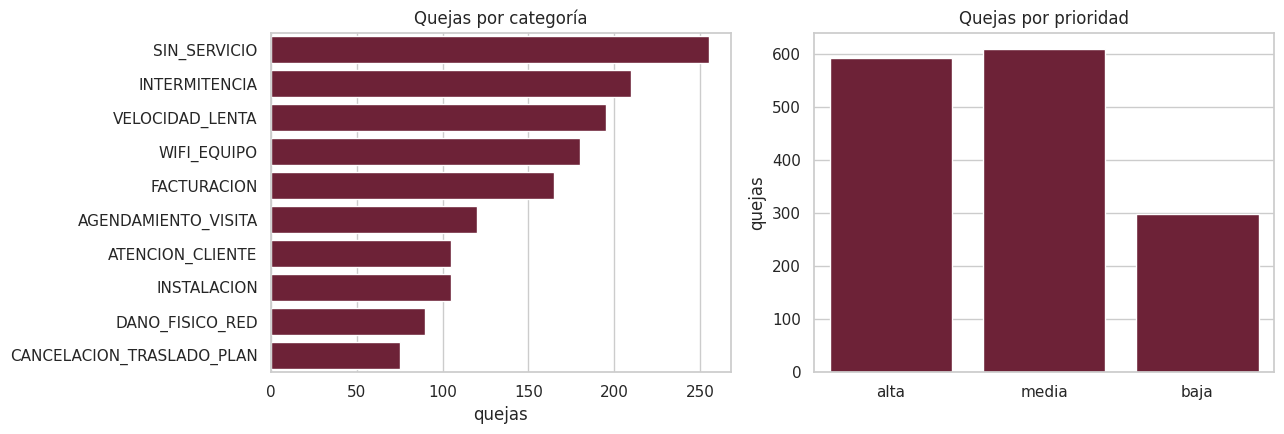

Razón de desbalance de categorías: 3.4 : 1


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
orden = df["categoria"].value_counts().index
sns.countplot(data=df, y="categoria", order=orden, color=GRANATE, ax=ax[0])
ax[0].set_title("Quejas por categoría"); ax[0].set_xlabel("quejas"); ax[0].set_ylabel("")
sns.countplot(data=df, x="prioridad", order=["alta", "media", "baja"], color=GRANATE, ax=ax[1])
ax[1].set_title("Quejas por prioridad"); ax[1].set_xlabel(""); ax[1].set_ylabel("quejas")
guardar_fig("01_distribucion_etiquetas")
cat = df["categoria"].value_counts()
print(f"Razón de desbalance de categorías: {cat.max() / cat.min():.1f} : 1")

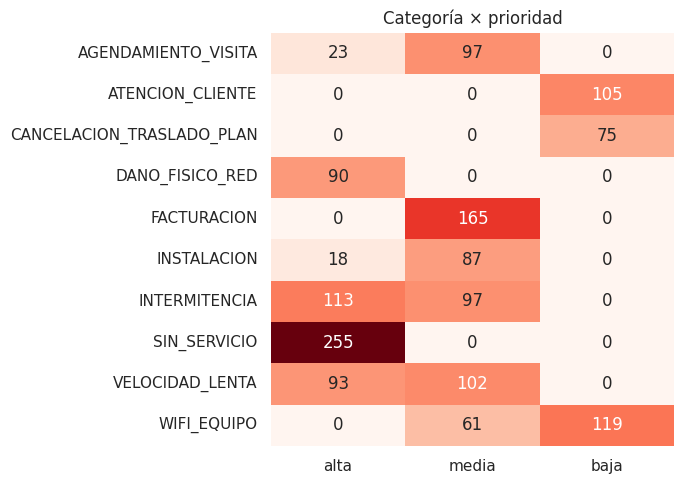

Categorías con una sola prioridad (por regla de la guía de etiquetado): ['ATENCION_CLIENTE', 'CANCELACION_TRASLADO_PLAN', 'DANO_FISICO_RED', 'FACTURACION', 'SIN_SERVICIO']


In [5]:
ct = pd.crosstab(df["categoria"], df["prioridad"])[["alta", "media", "baja"]]
plt.figure(figsize=(7, 5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Reds", cbar=False)
plt.title("Categoría × prioridad"); plt.ylabel(""); plt.xlabel("")
guardar_fig("01_categoria_por_prioridad")
fijas = [c for c in ct.index if (ct.loc[c] > 0).sum() == 1]
print("Categorías con una sola prioridad (por regla de la guía de etiquetado):", fijas)

La prioridad depende en parte de la categoría **por diseño** (por ejemplo, *sin servicio* siempre es alta). En las demás categorías depende de hechos del texto: dependencia crítica del servicio, días con el problema y reclamos previos (ver `data/guia_etiquetado.md`).

## 2. Subgrupos (base de la evaluación de equidad)

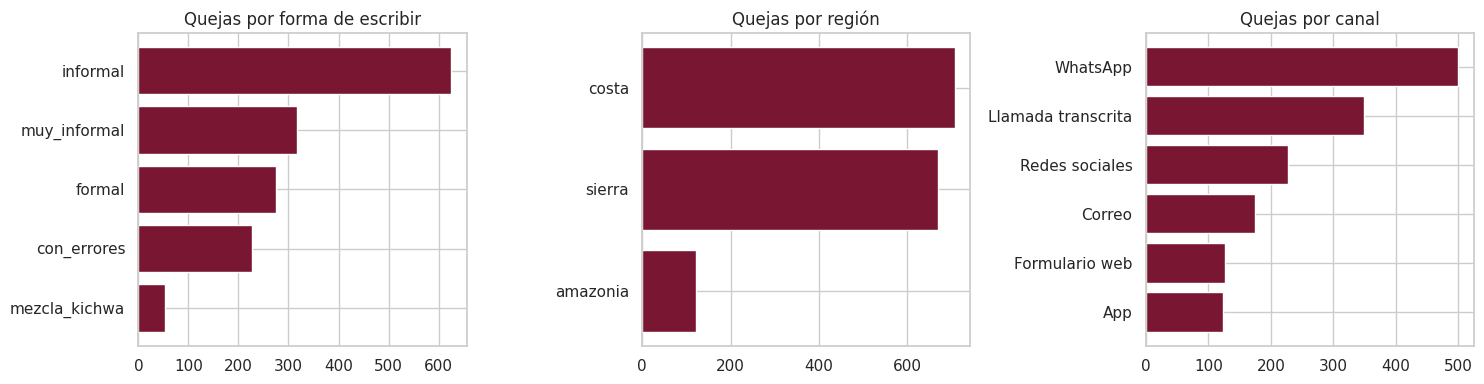

,registro,region,canal
informal,89,0,0
muy_informal,43,0,0
con_errores,32,0,0
formal,31,0,0
mezcla_kichwa,5,0,0
sierra,0,93,0
costa,0,93,0
amazonia,0,14,0
WhatsApp,0,0,64
Llamada transcrita,0,0,45


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["registro", "region", "canal"]):
    vc = df[col].value_counts()
    a.barh(vc.index[::-1], vc.values[::-1], color=GRANATE)
    a.set_title("Quejas por " + {"registro": "forma de escribir", "region": "región", "canal": "canal"}[col])
guardar_fig("01_subgrupos")
n_prueba = {c: df[df["conjunto"] == "prueba"][c].value_counts().to_dict() for c in ["registro", "region", "canal"]}
pd.DataFrame(n_prueba).fillna(0).astype(int)

La tabla anterior muestra cuántas quejas de cada subgrupo hay en la **prueba** (200). Los subgrupos con menos de 30 casos (por ejemplo, la mezcla con kichwa) se reportarán con su intervalo de confianza, sin sacar conclusiones de ellos por separado (retroalimentación de la Semana 4).

## 3. Longitud de los textos

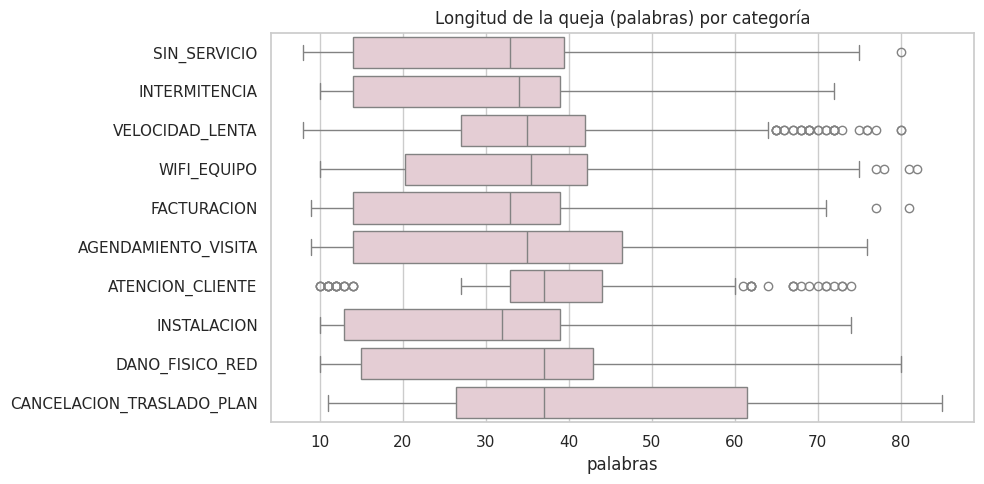

,palabras
count,1500.0
mean,35.2
std,18.6
min,8.0
25%,15.0
50%,34.0
75%,42.0
max,85.0


In [7]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, y="categoria", x="palabras", order=orden, color="#e8c9d2")
plt.title("Longitud de la queja (palabras) por categoría"); plt.ylabel("")
guardar_fig("01_longitud_por_categoria")
df["palabras"].describe().round(1)

## 4. Vocabulario por categoría

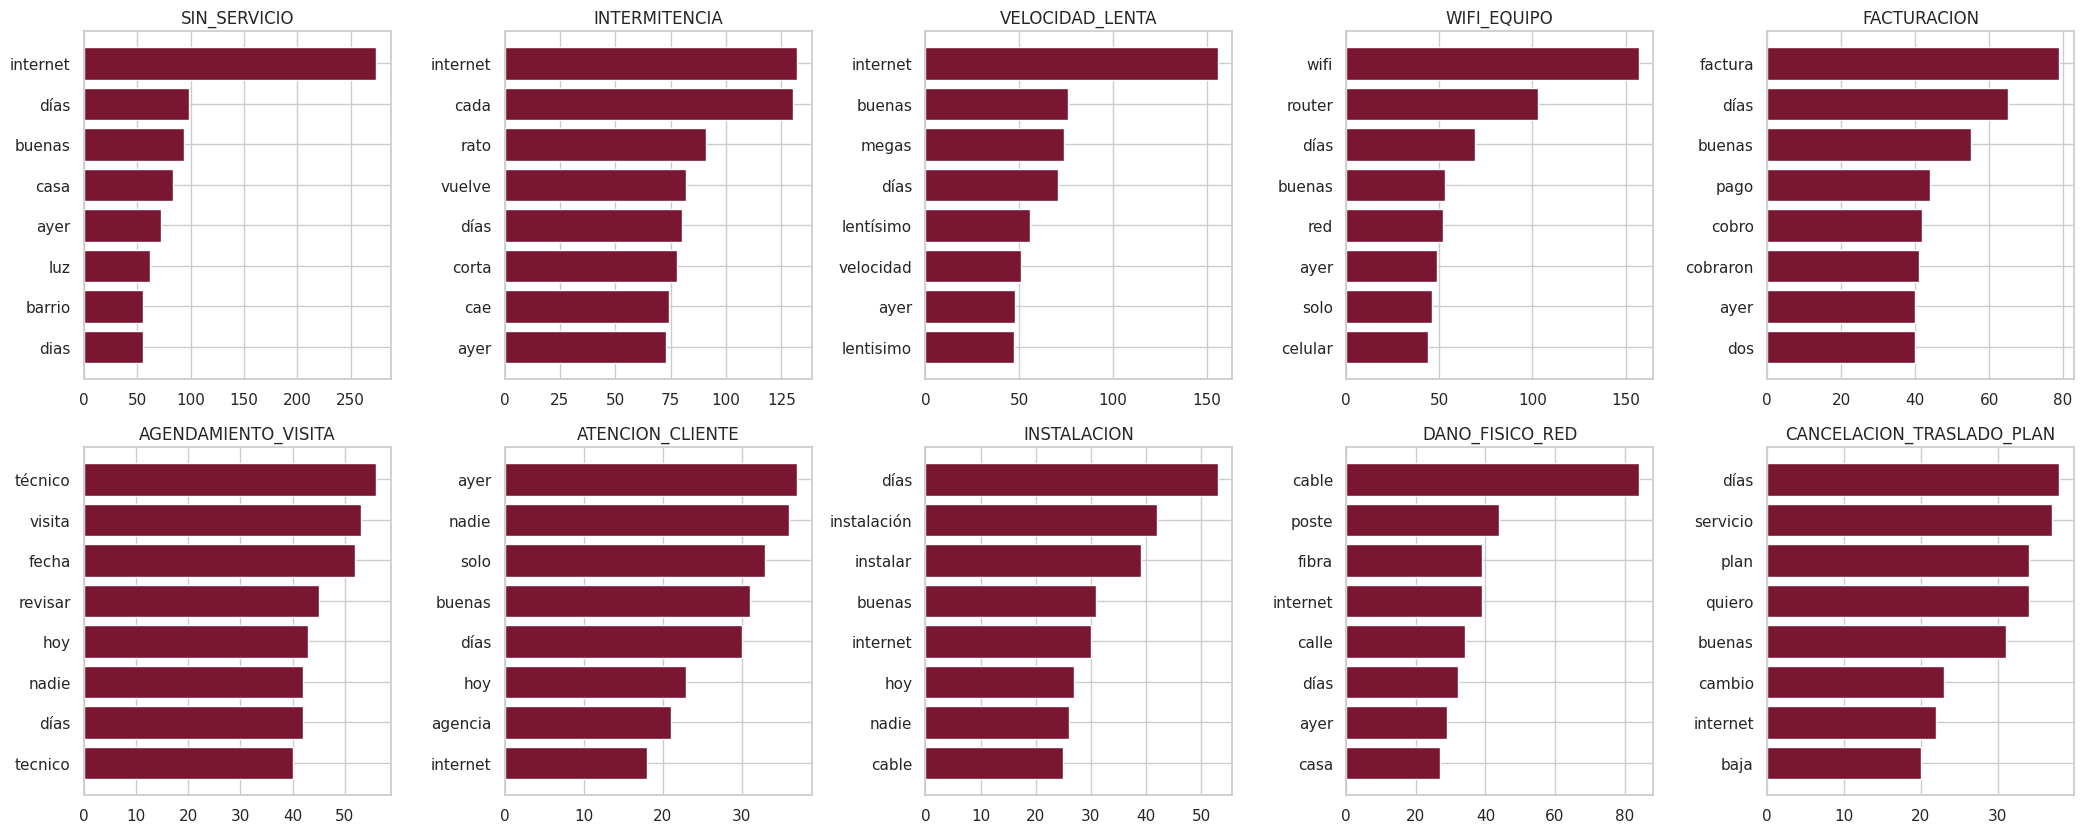

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from src.model import VACIAS
cv = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[a-záéíóúñü]{3,}\b", stop_words=list(VACIAS))
X = cv.fit_transform(df["queja"]); voc = np.array(cv.get_feature_names_out())
fig, ax = plt.subplots(2, 5, figsize=(21, 8.5))
for a, c in zip(ax.ravel(), orden):
    fr = np.asarray(X[(df["categoria"] == c).values].sum(axis=0)).ravel()
    top = fr.argsort()[::-1][:8]
    a.barh(voc[top][::-1], fr[top][::-1], color=GRANATE); a.set_title(c, fontsize=12); a.tick_params(labelsize=11)
guardar_fig("01_palabras_por_categoria")

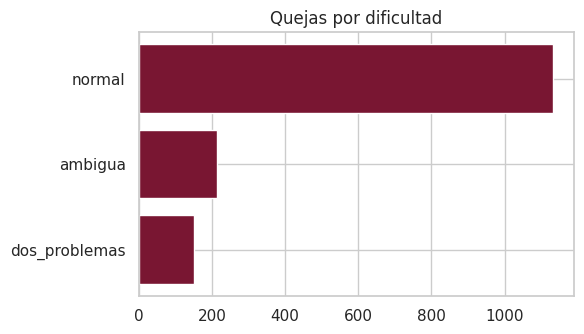

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
vc = df["dificultad"].value_counts()
ax.barh(vc.index[::-1], vc.values[::-1], color=GRANATE); ax.set_title("Quejas por dificultad")
guardar_fig("01_dificultad")

## 5. Resumen

- Corpus sin vacíos ni ids repetidos; prueba fija de 200 quejas.
- Desbalance moderado de categorías: justifica **F1-macro** como métrica principal y `class_weight='balanced'`.
- Subgrupos pequeños en la prueba: se reportan con n e intervalo de confianza.
- El vocabulario de cada categoría es propio del tema (no hay frases plantilla; ver `data/generacion/reporte_validacion.md`).

In [10]:
resumen = {"n": len(df), "por_conjunto": df["conjunto"].value_counts().to_dict(),
           "categoria": df["categoria"].value_counts().to_dict(), "prioridad": df["prioridad"].value_counts().to_dict(),
           "desbalance_categorias": float(cat.max() / cat.min()), "palabras": df["palabras"].describe().round(2).to_dict(),
           "n_prueba_por_subgrupo": n_prueba, "categorias_prioridad_fija": fijas}
guardar_json(resumen, f"{MET}/01_exploracion.json")

PosixPath('/content/drive/MyDrive/triajeia-isp/results/metrics/01_exploracion.json')

In [11]:
# Guarda el registro del entorno. En Colab, los resultados ya quedaron en Google Drive
# (MyDrive/triajeia-isp/results y models). Descargue además este notebook con sus salidas:
# Archivo → Descargar → .ipynb, y colóquelo en notebooks/ del repositorio.
guardar_json(entorno(), f"{MET}/entorno_{NB}.json")
print("Listo:", NB)

Listo: 01
